In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import detector_model as dm

In [2]:
detector = dm.Detector()
source_center = dm.Source()

rng = np.random.default_rng(2026)

Q1 = dm.simulate_sample(
    detector,
    source_center,
    E=1.0,
    n_events=1000,
    rng=rng
)

print("Средний сигнал:", Q1.mean())
print("Стандартное отклонение:", Q1.std(ddof=1))
print(
    "Относительная ширина:",
    Q1.std(ddof=1) / Q1.mean()
)

Средний сигнал: 124.983
Стандартное отклонение: 13.516856750606497
Относительная ширина: 0.10814956234533094


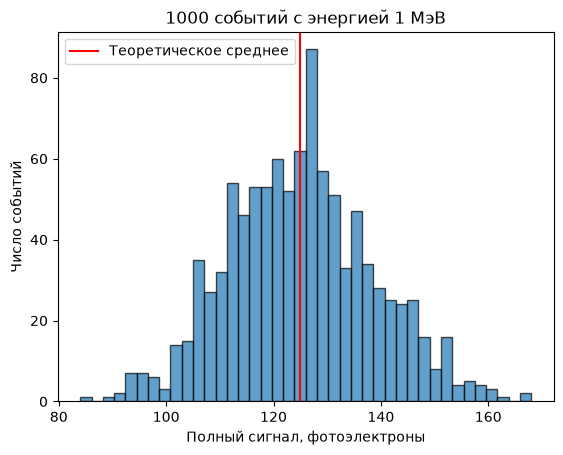

In [3]:
plt.hist(
    Q1,
    bins=40,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    125,
    color="red",
    label="Теоретическое среднее"
)

plt.xlabel("Полный сигнал, фотоэлектроны")
plt.ylabel("Число событий")
plt.title("1000 событий с энергией 1 МэВ")

plt.legend()
plt.show()

In [4]:
energies = np.array([
    0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0
])

n_events = 1000

rng_center = np.random.default_rng(2026)

center_samples = {}

for E in energies:
    center_samples[E] = dm.simulate_sample(
        detector,
        source_center,
        E,
        n_events,
        rng_center
    )

    print("Симуляция завершена для", E, "МэВ")

Симуляция завершена для 0.2 МэВ
Симуляция завершена для 0.5 МэВ
Симуляция завершена для 0.7 МэВ
Симуляция завершена для 1.0 МэВ
Симуляция завершена для 1.5 МэВ
Симуляция завершена для 2.0 МэВ
Симуляция завершена для 3.0 МэВ


In [5]:
means = np.array([
    center_samples[E].mean()
    for E in energies
])

sigmas = np.array([
    center_samples[E].std(ddof=1)
    for E in energies
])

relative_widths = sigmas / means

for E, mean, sigma, width in zip(
    energies,
    means,
    sigmas,
    relative_widths
):
    print(
        f"E={E:.1f} МэВ: "
        f"среднее={mean:.2f}, "
        f"σ={sigma:.2f}, "
        f"σ/среднее={100 * width:.2f}%"
    )

E=0.2 МэВ: среднее=24.90, σ=6.02, σ/среднее=24.17%
E=0.5 МэВ: среднее=63.03, σ=9.93, σ/среднее=15.75%
E=0.7 МэВ: среднее=87.78, σ=11.73, σ/среднее=13.37%
E=1.0 МэВ: среднее=124.83, σ=13.96, σ/среднее=11.18%
E=1.5 МэВ: среднее=186.93, σ=16.57, σ/среднее=8.86%
E=2.0 МэВ: среднее=250.07, σ=19.14, σ/среднее=7.65%
E=3.0 МэВ: среднее=374.58, σ=22.43, σ/среднее=5.99%


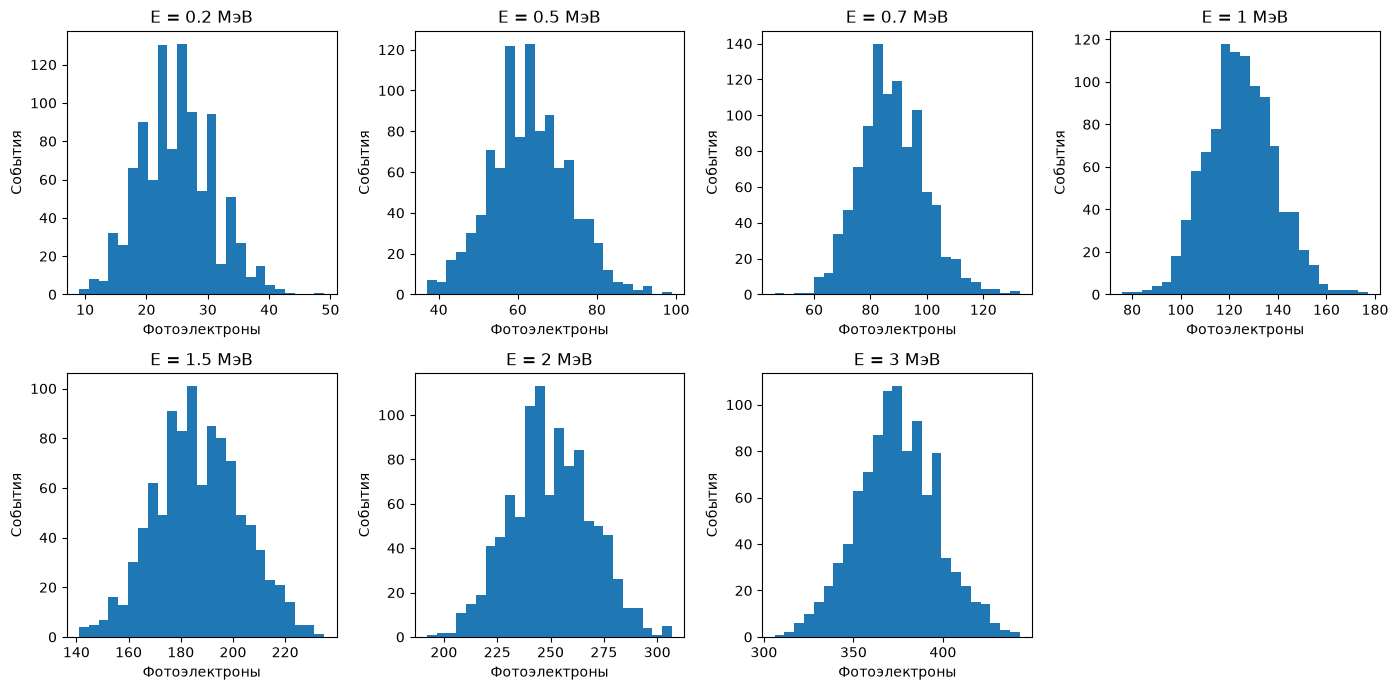

In [6]:
fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7)
)

for ax, E in zip(axes.flat, energies):
    ax.hist(center_samples[E], bins=25)

    ax.set_title(f"E = {E:g} МэВ")
    ax.set_xlabel("Фотоэлектроны")
    ax.set_ylabel("События")

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

In [7]:
coverage = (
    detector.N * detector.r**2
    / (4 * detector.R**2)
)

expected_means = (
    detector.a
    * source_center.Y
    * energies
    * coverage
)

expected_widths = np.sqrt(
    (1 + detector.a * (1 - coverage))
    / expected_means
)

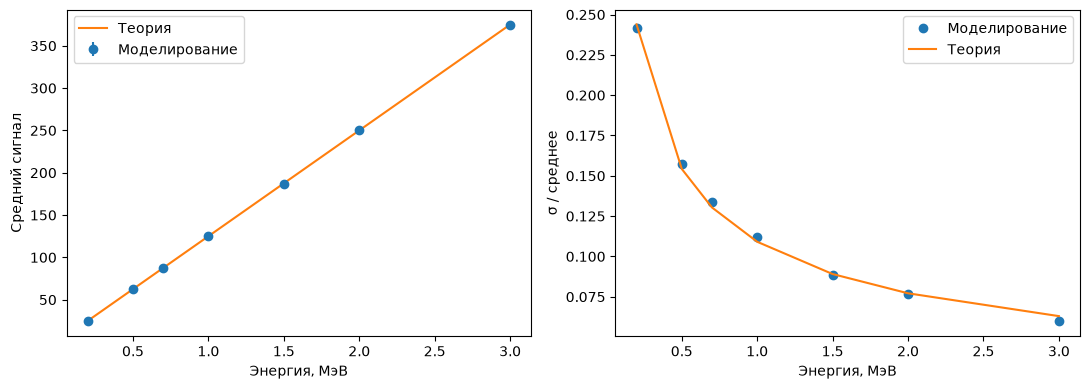

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].errorbar(
    energies,
    means,
    yerr=sigmas / np.sqrt(n_events),
    fmt="o",
    label="Моделирование"
)

axes[0].plot(
    energies,
    expected_means,
    label="Теория"
)

axes[0].set_xlabel("Энергия, МэВ")
axes[0].set_ylabel("Средний сигнал")
axes[0].legend()

axes[1].plot(
    energies,
    relative_widths,
    "o",
    label="Моделирование"
)

axes[1].plot(
    energies,
    expected_widths,
    label="Теория"
)

axes[1].set_xlabel("Энергия, МэВ")
axes[1].set_ylabel("σ / среднее")
axes[1].legend()

plt.tight_layout()
plt.show()

Сместим источник на 1 метр вдоль z

In [9]:
source_shifted = dm.Source(
    position=(0.0, 0.0, 1.0)
)

rng_shifted = np.random.default_rng(2027)

shifted_samples = {}

for E in energies:
    shifted_samples[E] = dm.simulate_sample(
        detector,
        source_shifted,
        E,
        n_events,
        rng_shifted
    )

    print("Симуляция завершена для", E, "МэВ")

Симуляция завершена для 0.2 МэВ
Симуляция завершена для 0.5 МэВ
Симуляция завершена для 0.7 МэВ
Симуляция завершена для 1.0 МэВ
Симуляция завершена для 1.5 МэВ
Симуляция завершена для 2.0 МэВ
Симуляция завершена для 3.0 МэВ


In [10]:
for E in energies:
    q_center = center_samples[E]
    q_shifted = shifted_samples[E]

    mean_center = q_center.mean()
    mean_shifted = q_shifted.mean()

    se_center = (
        q_center.std(ddof=1)
        / np.sqrt(n_events)
    )

    se_shifted = (
        q_shifted.std(ddof=1)
        / np.sqrt(n_events)
    )

    difference = mean_shifted - mean_center

    difference_error = np.sqrt(
        se_center**2 + se_shifted**2
    )

    relative_change = (
        100 * difference / mean_center
    )

    print(
        f"E={E:.1f} МэВ: "
        f"центр={mean_center:.2f}, "
        f"смещение={mean_shifted:.2f}, "
        f"разность={difference:.2f} ± "
        f"{difference_error:.2f}, "
        f"изменение={relative_change:.2f}%"
    )

E=0.2 МэВ: центр=24.90, смещение=25.09, разность=0.20 ± 0.27, изменение=0.80%
E=0.5 МэВ: центр=63.03, смещение=62.36, разность=-0.67 ± 0.44, изменение=-1.07%
E=0.7 МэВ: центр=87.78, смещение=87.41, разность=-0.37 ± 0.52, изменение=-0.42%
E=1.0 МэВ: центр=124.83, смещение=125.14, разность=0.31 ± 0.62, изменение=0.25%
E=1.5 МэВ: центр=186.93, смещение=186.67, разность=-0.26 ± 0.73, изменение=-0.14%
E=2.0 МэВ: центр=250.07, смещение=248.13, разность=-1.94 ± 0.86, изменение=-0.77%
E=3.0 МэВ: центр=374.58, смещение=375.13, разность=0.55 ± 1.04, изменение=0.15%


Сравним распределения при 1 МэВ с одинаковыми границами столбцов:

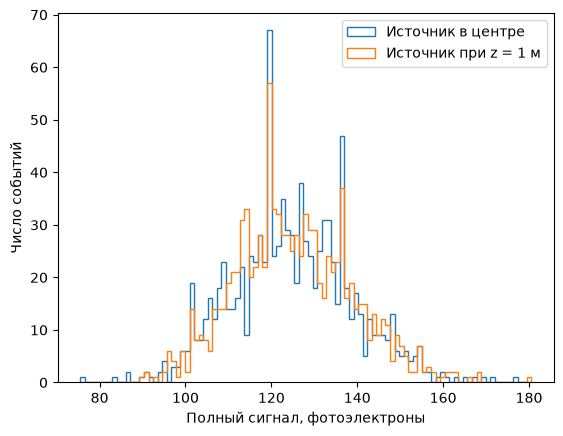

In [11]:
q_center = center_samples[1.0]
q_shifted = shifted_samples[1.0]

bins = np.linspace(
    min(q_center.min(), q_shifted.min()) - 0.5,
    max(q_center.max(), q_shifted.max()) + 0.5,
    100
)

plt.hist(
    q_center,
    bins=bins,
    histtype="step",
    label="Источник в центре"
)

plt.hist(
    q_shifted,
    bins=bins,
    histtype="step",
    label="Источник при z = 1 м"
)

plt.xlabel("Полный сигнал, фотоэлектроны")
plt.ylabel("Число событий")
plt.legend()

plt.show()

Ближние ФЭУ получают больше света, дальние — меньше. При достаточно равномерном покрытии эти изменения в значительной степени компенсируются в полном сигнале.

Для идеального непрерывного равномерного покрытия средняя доля зарегистрированного света вообще не зависела бы от положения источника. У нас всего 40 отдельных участков, поэтому точной независимости нет.